# Week 5 · Numerical data with numpy

**CM3801 · CMT309/509 · CMT124** · shared session · Thursday 5 November 2026

Data science runs on numbers: sensor readings, prices, pixel values, word counts. Python lists can hold numbers, but they are slow and clumsy for maths on thousands of values. **numpy** gives you a fast array type and the tools to compute with whole arrays at once.

By the end of today you can create **arrays** and inspect their shape and type, replace loops with **vectorised** operations, select data with **slicing, integer and Boolean indexing**, explain **broadcasting**, multiply matrices with `@`, and compute **descriptive statistics** (mean, median, variance, correlation).

Today has three teaching parts and a lab: **Hour 1** arrays and vectorisation · **Hour 2** selecting and combining · **Hour 3** linear algebra and descriptive statistics · **Lab** a week of hourly temperatures.

## Hour 1 · Arrays and vectorisation

### Where numbers fit

Data comes from many **sources**: *structured* tables (age, height, speed), *unstructured* text, images and sound, and *semi-structured* data tagged with metadata (creator, date, location). Whatever the source, a pipeline cleans, transforms and analyses it, and most of that work happens on **numbers**: text becomes word counts, images become pixel values, sound becomes samples.

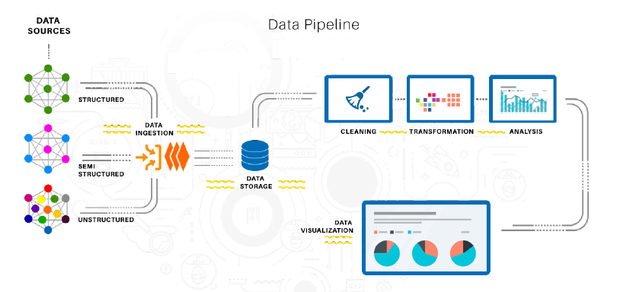

Linear algebra gives the containers names. A single number is a **scalar**, a line of numbers a **vector**, a grid a **matrix**, and anything with three or more dimensions a **tensor**.

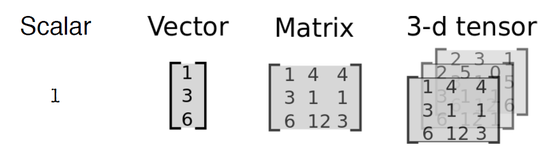

### The `ndarray`

numpy (**Num**erical **Py**thon) stores all of these in one type, the **`ndarray`** (n-dimensional array). It is the foundation of pandas, matplotlib, SciPy and scikit-learn, so everything you learn today comes back in later weeks.

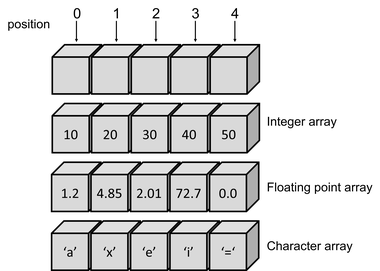

| Python list | numpy `ndarray` |
|---|---|
| `[1, "two", [1, 2]]`: any mix of types | `np.array([1, 2, 3])`: **one** type (`dtype`) for every element |
| grows and shrinks (`append`) | **fixed size** once created |
| mutable | mutable (values can change) |

Less flexible, but it uses far less memory, runs much faster, and comes with optimised maths.

In [ ]:
import numpy as np

a = np.array([0, 1, 2, 3])
print(type(a), a)
print(a.dtype, a.ndim, a.shape)

`dtype` is the element type (`int64`: 64-bit integers), `ndim` the number of dimensions, and `shape` the length along each dimension. `(4,)` is a tuple with one item: one dimension of length 4.

**Predict:** every element must have the same type. What is the `dtype` of `np.array([1, 2.5])`?

In [ ]:
b = np.array([1, 2.5])
print(b, b.dtype)

`float64`. numpy **upcasts** to a type that can hold every value, so `1` becomes `1.`. You can also choose the type yourself, or convert (**cast**) an existing array with `.astype()`:

In [ ]:
print(np.array([1, 2, 3, 4], dtype=float))
counts = np.arange(4)
print(counts.astype(float), counts.dtype)

`.astype()` returns a **new** array: `counts` itself is still `int64`.

### More dimensions

numpy counts dimensions from the **outside in**: columns are always the last dimension, rows the second last, and any extra dimension is added at the front.

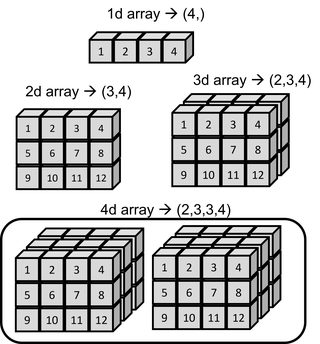

**Quick check:** what is the `shape` of an array with 2 rows and 3 columns?
(a) `(3, 2)` · (b) `(2, 3)` · (c) `6` · (d) `(6,)`

In [ ]:
m = np.array([[1, 2, 3], [4, 5, 6]])
print(m)
print(m.shape, m.ndim, m.size)
print(np.arange(6).reshape(2, 3))

(b) `(2, 3)`: rows first, then columns. `size` is the total number of elements (6), and `.reshape(2, 3)` arranges six values into the same shape. A reshape must keep the number of elements: `np.arange(6).reshape(4, 2)` fails.

### Creating arrays

| To create | Use | Example |
|---|---|---|
| from a list or nested list | `np.array()` | `np.array([[1, 2], [3, 4]])` |
| a range of numbers | `np.arange()` | `np.arange(0, 10, 2)` |
| evenly spaced values | `np.linspace()` | `np.linspace(1, 2, 5)` |
| zeros / ones | `np.zeros()`, `np.ones()` | `np.zeros((2, 3))` (the shape is a tuple) |
| an identity matrix | `np.eye()` | `np.eye(3)` |
| random numbers | a random generator | see below |

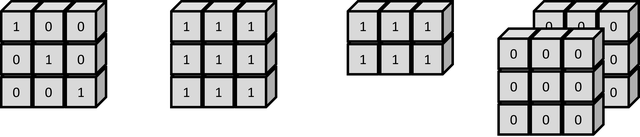

In [ ]:
print(np.zeros((2, 3)))
print(np.eye(3))
print(np.linspace(1, 2, 5))

**Random numbers.** Create a **random generator** with a fixed **seed**: everyone who uses the same seed gets the same "random" numbers, so results can be reproduced.

In [ ]:
rng = np.random.default_rng(42)
print(rng.normal(size=3))             # three values from a normal (Gaussian) distribution
print(rng.integers(1, 7, size=10))    # ten dice rolls: 1 to 6 (7 is excluded)

Run the cell twice: the numbers stay the same, because the generator is re-created with seed `42` each time.

### Vectorisation: no loops needed

How do you multiply every element of an array by 10? With a list you would write a loop. With an array you write the operation **once**, and numpy applies it to every element.

In [ ]:
# ✍️ Type along: multiply every value by 10, first with a loop, then vectorised
a = np.arange(1000)

<details><summary>Code from class</summary>

```python
a = np.arange(1000)
for i in range(1000):      # correct, but slow
    a[i] *= 10
print(a[:5])

b = np.arange(1000)
b *= 10                    # vectorised: one operation on the whole array
print(b[:5])
print((a == b).all())      # same result
```

</details>

Replacing a `for` or `while` loop with a single array operation is called **vectorisation**. Arithmetic works **element-wise**, with a scalar or with a function:

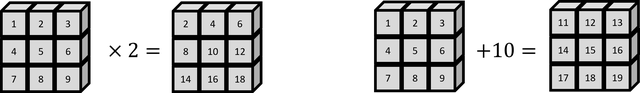

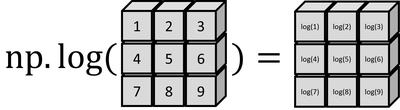

`np.log(a)` takes the log of **each element** (not a "matrix logarithm"). `+ - * / ** // %` all work the same way.

**Predict:** the next cell times a list comprehension and the vectorised version on 100,000 numbers. How many times faster will numpy be: 2×, 10× or 100×?

In [ ]:
values = list(range(100_000))
arr = np.arange(100_000)
%timeit -n 3 -r 3 [v * 10 for v in values]
%timeit -n 3 -r 3 arr * 10

On most machines the array version is **tens to hundreds of times** faster (exact numbers vary). `%timeit` is a notebook command that runs a line several times and reports the average.

### Summaries along an axis

numpy has fast versions of `sum`, `max` and `min`, plus `argmax`/`argmin` (the **position** of the largest/smallest value).

**Before we run this:** `a` has 2 rows. What could Python's built-in `sum(a)` give, compared with `np.sum(a)`?

In [ ]:
a = np.array([50, 5, 1, 100, 0, 10]).reshape(2, 3)
print(a)
print(np.sum(a), sum(a))
print(a.max(), a.min(), a.argmax(), a.argmin())

`np.sum(a)` adds all six values (166). Python's `sum(a)` adds the **rows** together and returns `[150, 5, 11]`: use the numpy version. `argmax()` counts positions as if the array were flat: `100` is at position 3.

With **`axis`** you summarise in one direction only:

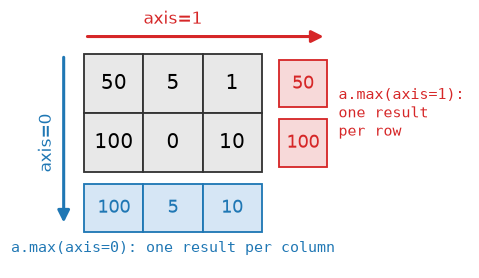

In [ ]:
print(a.max(axis=0))
print(a.max(axis=1))
print(a.mean(axis=1))

**Your turn:** `temps_c` holds a week of daily maximum temperatures in °C. Without a loop:
1. convert them all to Fahrenheit (`F = C × 9/5 + 32`);
2. print the highest Fahrenheit value **and** the day (0 = Monday) on which it occurred.

In [ ]:
temps_c = np.array([14.5, 16.0, 12.5, 18.5, 17.0, 11.5, 15.0])
# your code here

<details><summary>Answer</summary>

```python
temps_f = temps_c * 9 / 5 + 32      # one vectorised expression
print(temps_f)
print(temps_f.max(), temps_f.argmax())   # 65.3 on day 3 (Thursday)
```

</details>

### Takeaways: arrays and vectorisation

* An `ndarray` has **one `dtype`** and a **`shape`** (rows first, then columns).
* Create arrays with `np.array`, `np.arange`, `np.zeros`, `np.linspace`; use a **seeded** `np.random.default_rng` for random numbers.
* Arithmetic and functions work **element-wise**: vectorise instead of looping.
* Use `np.sum`, `.max()`, `.mean()`; `axis=0` gives one result per column, `axis=1` one per row.

## Hour 2 · Selecting and combining

### Comparisons give Boolean arrays

Comparison operators also work element-wise. The result is an array of `True`/`False` with the same shape.

<img alt="a > 4 and a < 7 give Boolean arrays; combining them gives where both are true" src="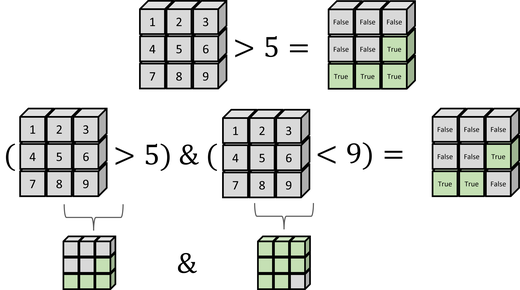">

In [ ]:
a = np.arange(9).reshape(3, 3)
print(a > 4)
print((a > 4) & (a < 7))

Combine Boolean arrays with `&` (and), `|` (or) and `~` (not), and put each comparison in **brackets**. Python's `and`/`or` don't work element-wise on arrays.

### Array with array

Two arrays of the **same shape** combine element by element: `+`, `-`, `*`, `/`. Note that `*` is **not** matrix multiplication (that is Hour 3).

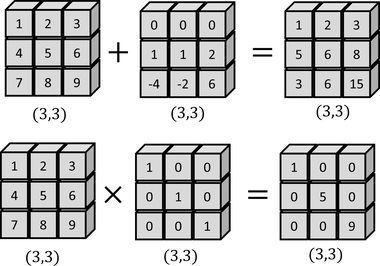

In [ ]:
a = np.arange(1, 10).reshape(3, 3)
print(a * np.eye(3))      # element-wise: keeps only the diagonal

### Picking single elements

Positions start at **0** in every dimension. A 2-D array takes `a[row, column]`; `a[row][column]` also works, as with nested lists.

![a[0,1], a[0,3] or a[0,-1] and a[2,2] in a (3,4) array; three indices in a (2,3,4) array](attachment:accessing.png)
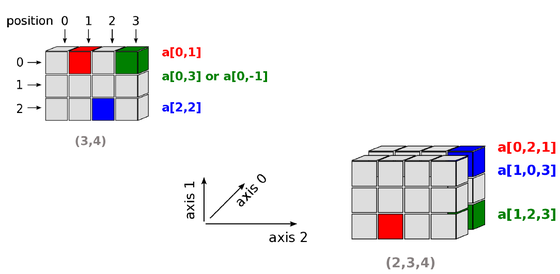

**Quick check:** with `a = np.array([[0, 1, 2], [3, 4, 5], [6, 7, 8]])`, which expression gives the `5`?
(a) `a[1, 3]` · (b) `a[1, 2]` · (c) `a[0, 2]`

<details><summary>Answer</summary>

(b) `a[1, 2]`: row 1, column 2. (a) fails with an `IndexError`, because there is no column 3.

</details>

### Slicing in one and two dimensions

`arr[start:stop:step]` works as with lists: `stop` is excluded, and any part can be left out. With two dimensions, give one slice **per dimension**, separated by a comma.

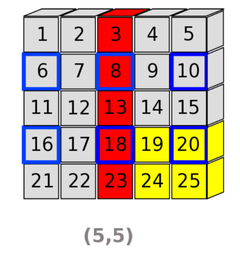

In [ ]:
# ✍️ Type along: the red column, the blue grid and the yellow corner
a = np.arange(1, 26).reshape(5, 5)

<details><summary>Code from class</summary>

```python
a = np.arange(1, 26).reshape(5, 5)
print(a)
print(a[:, 2])          # red: every row, column 2   -> [ 3  8 13 18 23]
print(a[1::2, 0::2])    # blue: rows 1 and 3, every second column
print(a[3:, 3:])        # yellow: the bottom-right 2 x 2 corner
```

</details>

**Predict:** using the same 5 × 5 array, what does `a[1:3, ::2]` return? Write down the shape first.

In [ ]:
a = np.arange(1, 26).reshape(5, 5)
print(a[1:3, ::2])
print(a[1:3, ::2].shape)

Rows 1 and 2, columns 0, 2 and 4: `[[6, 8, 10], [11, 13, 15]]`, shape `(2, 3)`.

The shape tells you what a selection keeps. A single index **drops** a dimension; a slice keeps it:

![Slices of a 3 by 3 array and their shapes: arr[:2, 1:] is (2, 2); arr[2] is (3,); arr[2:, :] is (1, 3)](attachment:slicing_shapes.png)

*Figure: after Wes McKinney, Python for Data Analysis (O'Reilly).*

**Try it:** with `arr = np.arange(9).reshape(3, 3)`, check two rows of the figure: compare `arr[2].shape` with `arr[2:, :].shape`.
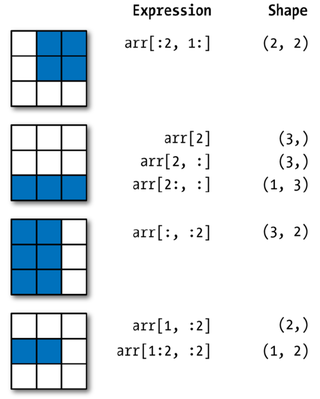

In [ ]:
arr = np.arange(9).reshape(3, 3)
# your code here

<details><summary>Answer</summary>

```python
print(arr[2], arr[2].shape)          # [6 7 8] (3,)      one index: a 1-d row
print(arr[2:, :], arr[2:, :].shape)  # [[6 7 8]] (1, 3)  a slice: still 2-d
```

</details>

### Integer indexing

A **list of positions** picks individual elements: the first list gives the rows, the second the columns, pair by pair.

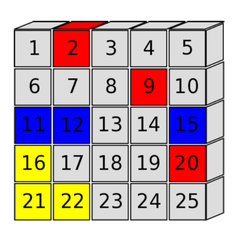

In [ ]:
a = np.arange(1, 26).reshape(5, 5)
print(a[[0, 1, 3], [1, 3, 4]])    # red: (0,1), (1,3), (3,4)
print(a[[2, 2, 2], [0, 1, 4]])    # blue

### Boolean indexing

A Boolean array of the same shape can be used **as an index**: it keeps the elements where it is `True`. The result is always 1-d.

<img alt="The mask a > 0 selects 2, 12, 15, 1 and 100 from a 3 by 3 array" src="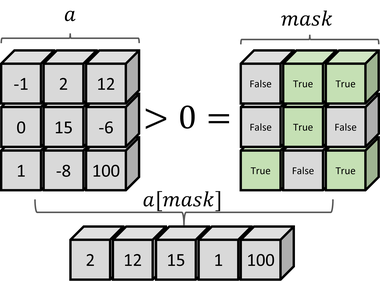">

In [ ]:
a = np.array([-1, 2, 12, 0, 15, -6, 1, -8, 100]).reshape(3, 3)
mask = a > 0
print(mask)
print(a[mask], a[a > 0].sum())

**Your turn:** use Boolean indexing to select the elements marked in yellow, with one expression.

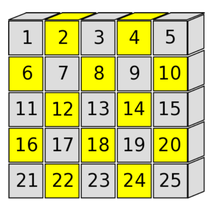

In [ ]:
a = np.arange(1, 26).reshape(5, 5)
# your code here

<details><summary>Answer</summary>

```python
a[a % 2 == 0]       # array([ 2,  4,  6,  8, 10, 12, 14, 16, 18, 20, 22, 24])
```

Count them without listing them: `(a % 2 == 0).sum()` gives 12, because `True` counts as 1.

</details>

### Broadcasting

So far: an array with a scalar, and two arrays of the same shape. **Broadcasting** lets numpy combine arrays whose shapes **don't** match, by stretching the smaller one.

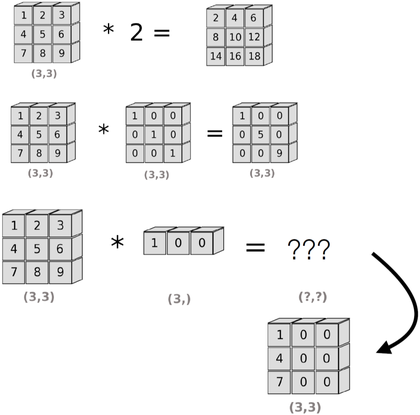

numpy compares the shapes **from the right**:
1. If one array has fewer dimensions, its shape is padded with 1s on the **left**: `(3,)` becomes `(1, 3)`.
2. A dimension of size **1** is stretched to match the other array.
3. If sizes differ and **neither** is 1, numpy raises an error.

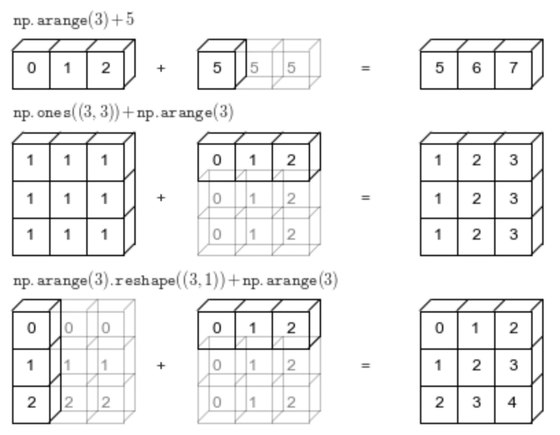

In [ ]:
print(np.ones((3, 3)) + np.arange(3))                 # (3,3) + (3,): the row is repeated
print(np.arange(3).reshape(3, 1) + np.arange(3))     # (3,1) + (3,): both are stretched

**Before we run this:** apply the three rules to shapes `(3, 3)` and `(2,)`. Will it work?

In [ ]:
# ⚠️ This cell raises an error on purpose
np.arange(9).reshape(3, 3) + np.arange(2)

Rule 1 pads `(2,)` to `(1, 2)`; rule 2 stretches the 1 to 3, giving `(3, 2)`; but the last dimensions are 3 and 2, and neither is 1. Rule 3: `ValueError: operands could not be broadcast together`. When you see it, **print the shapes**.

### Takeaways: selecting and combining

* Comparisons give Boolean arrays; combine them with `&`, `|`, `~` and brackets.
* `a[row, col]`, slices per dimension (`a[1:3, ::2]`); a single index drops a dimension.
* Integer indexing picks positions; **Boolean indexing** (`a[a > 0]`) filters values.
* **Broadcasting** compares shapes from the right; size-1 dimensions stretch, other mismatches fail.

## Hour 3 · Linear algebra and descriptive statistics

### Transpose

`.T` swaps rows and columns: row *i* becomes column *i*. A `(2, 3)` array becomes `(3, 2)`.

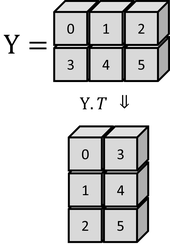

In [ ]:
Y = np.arange(6).reshape(2, 3)
print(Y)
print(Y.T, Y.T.shape)

### Matrix products with `@`

`*` multiplies element by element. The **`@`** operator performs the **matrix product**: each result is a row of the left array times a column of the right array, multiplied pair by pair and added up.

The rule for shapes: `(n, k) @ (k, m)` gives `(n, m)`. The **inner** sizes must be equal. With two 1-d arrays, `@` gives a single number (the dot product).

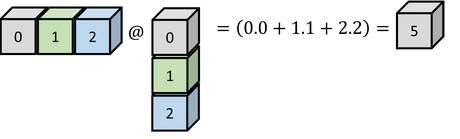

In [ ]:
# ✍️ Type along: z @ z, then z @ X @ z
z = np.arange(3)
X = np.arange(9).reshape(3, 3)

<details><summary>Code from class</summary>

```python
z = np.arange(3)                  # [0 1 2]
X = np.arange(9).reshape(3, 3)
print(z @ z)                      # 0*0 + 1*1 + 2*2 = 5
print(z @ X)                      # [15 18 21]
print(z @ X @ z)                  # [15 18 21] @ [0 1 2] = 60
```

</details>

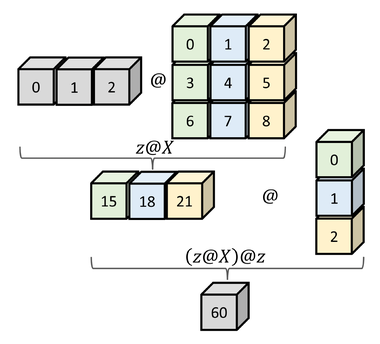

In [ ]:
X = np.arange(9).reshape(3, 3)
Y = np.arange(6).reshape(2, 3)
print(X.shape, Y.shape, Y.T.shape)

**Predict:** which of `X @ Y` and `X @ Y.T` fails, and what shape does the other one have?

In [ ]:
# ⚠️ This cell raises an error on purpose
X @ Y

In [ ]:
print(X @ Y.T)
print((X @ Y.T).shape)

`X @ Y` fails: `(3, 3) @ (2, 3)` has inner sizes 3 and 2 (the error says "mismatch in its core dimension"). Transposing `Y` gives `(3, 3) @ (3, 2)`: the inner sizes match and the result is `(3, 2)`.

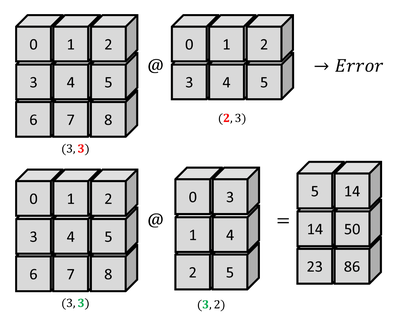

### Describing data

Suppose you have measured the height of many people: `[66, 61.5, 79, 70, 75, 67, ...]` (in inches). How would you **describe** these numbers to someone in one or two sentences? **Descriptive statistics** summarise data in three ways:
* **location** (central tendency): where is the middle?
* **spread** (dispersion): how far do values scatter?
* **association**: do two variables move together?

### Location: mean and median

The **mean** (sample average) adds the values and divides by how many there are:

$$\bar{x} = \frac{1}{N}\left(x_1 + x_2 + \dots + x_N\right) = \frac{1}{N}\sum_{i=1}^{N} x_i \qquad\text{e.g. } \tfrac{1}{4}(1 + 2 + 3 + 4) = 2.5$$

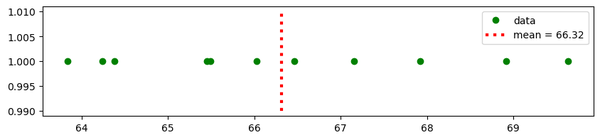

The **median** is the middle value once the data are sorted. With an even number of values, it is the average of the two middle ones: the median of `5, 2, 3, 1, 4` is 3; of `6, 5, 2, 3, 1, 4` it is 3.5.

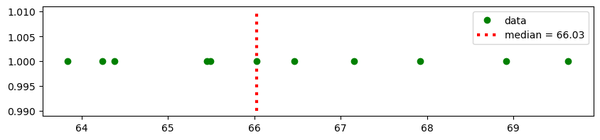

Now add one **outlier**, a value of 120. The mean jumps from 66.32 to 70.79:

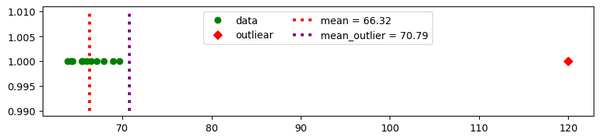

The median barely moves, from 66.03 to 66.24:

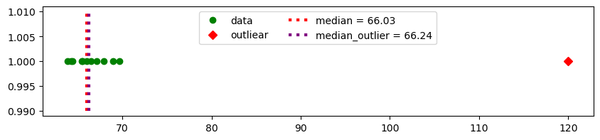

In [ ]:
x = np.array([1, 2, 3, 4])
print(np.mean(x), np.median(x))
x_out = np.append(x, 100)      # add an outlier
print(np.mean(x_out), np.median(x_out))

One outlier moves the mean from 2.5 to 22; the median only moves from 2.5 to 3. The mean uses every value's **size**; the median only uses the **order**.

**Discuss:** news reports on house prices usually quote the **median** price, not the mean. Why?

<details><summary>Answer</summary>

House prices are skewed: a few very expensive houses pull the mean up, so the mean is higher than what a typical buyer pays. The median is the price of the middle house and is robust to those outliers. The mean is still useful when you need totals (mean × number of houses = total value).

</details>

### Spread: variance and standard deviation

The **variance** measures the typical squared distance from the mean: each value's distance is squared (so the sign doesn't matter), the squares are added up and divided by $N - 1$:

$$\mathrm{Var}(x) = \frac{1}{N-1}\sum_{i=1}^{N}\left(x_i - \bar{x}\right)^2$$

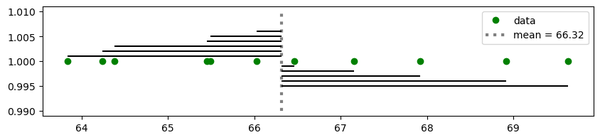

In [ ]:
h = np.array([66, 61.5, 79, 70, 75, 67, 68, 71.1, 78, 65, 66, 69])
print(np.var(h, ddof=1), np.std(h, ddof=1))
print(np.var(h))               # numpy's default divides by N

`ddof=1` gives the $N - 1$ version used above. The **standard deviation** `np.std` is the square root of the variance, in the original units (inches here).

### Association

Plotting each variable on its own tells us nothing about how they **relate**: is the tallest person also the heaviest?

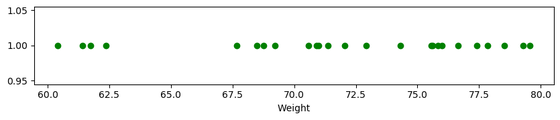

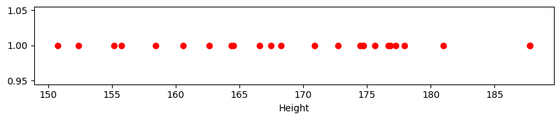

A **scatter plot** shows each person as one point (weight, height). Here the points form a loose cloud.

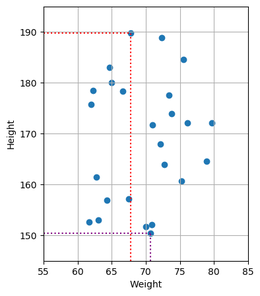

The **covariance** measures whether two variables move together: positive when large $x$ goes with large $y$:

$$\mathrm{Cov}(x, y) = \frac{1}{N-1}\sum_{i=1}^{N}\left(x_i - \bar{x}\right)\left(y_i - \bar{y}\right)$$

Covariance depends on the units (cm × kg), so it has no natural scale. The **correlation** divides by both standard deviations, which puts it between **−1** and **1**: 1 is a perfect positive relationship, 0 none, −1 a perfect negative one.

$$\mathrm{Corr}(x, y) = \frac{\mathrm{Cov}(x, y)}{\sqrt{\mathrm{Var}(x)\,\mathrm{Var}(y)}}$$

In [ ]:
height = np.array([150, 160, 170, 180, 190])
weight = np.array([55, 60, 72, 80, 88])
print(np.cov(height, weight))
print(np.corrcoef(height, weight)[0, 1])

`np.cov` and `np.corrcoef` return a **2 × 2 matrix**: the diagonal compares each variable with itself, and `[0, 1]` is the value for the pair. A correlation of about 0.99 means these five people lie almost on a straight line.

**Discuss:** we measure the height, weight and age of 100 adults aged 18 to 40. Which pairs (height–weight, height–age, age–weight) would you expect to be correlated? Does anything change for 100 children aged 1 to 12?

<details><summary>Answer</summary>

For adults, height and weight are positively correlated; height hardly changes with age between 18 and 40 (correlation near 0); age and weight may be weakly positive. For children, all three pairs are **strongly** positive, because children grow taller and heavier as they get older. Correlation depends on the group you measure.

</details>

**Your turn:** `prices` holds ten (made-up) house prices in £ thousands. Compute the mean and the median, then the mean **without** the outlier, using a Boolean mask. Finally print the standard deviation (`ddof=1`) with and without the outlier.

In [ ]:
prices = np.array([215, 240, 198, 260, 232, 1450, 225, 249, 210, 236])
# your code here

<details><summary>Answer</summary>

```python
print(prices.mean(), np.median(prices))      # 351.5 234.0
typical = prices[prices < 1000]               # Boolean indexing from Hour 2
print(typical.mean())                         # about 229.4
print(prices.std(ddof=1), typical.std(ddof=1))
```

One mansion pulls the mean above every other house; the median hardly notices it. The standard deviation, which is built on the mean, is inflated by the outlier too.

</details>

### Takeaways: linear algebra and statistics

* `.T` transposes; `@` is the matrix product: `(n, k) @ (k, m)` → `(n, m)`. `*` is element-wise.
* The **mean** is pulled by outliers; the **median** is robust.
* `np.var`/`np.std` with `ddof=1` divide by $N - 1$.
* **Association:** covariance (unit-dependent) and correlation (between −1 and 1) via `np.cov`, `np.corrcoef`.

## Transition to the lab

**You now know** how to build arrays, compute along an axis, select with slices and masks, combine shapes by broadcasting, and summarise data with mean, median, variance and correlation.

**The lab** (`W05_lab_student.ipynb`, one hour) puts these together on one array: a week of **hourly temperatures** (7 days × 24 hours). You will compute daily means with `axis`, count frost hours with a Boolean mask, find anomalies by broadcasting, see a faulty sensor reading pull the mean but not the median, and measure a correlation. Everything uses only what you met today.

## Week 5 takeaways

* An `ndarray` has one `dtype` and a `shape`; operations are **element-wise** and fast: vectorise, don't loop.
* `axis=0` summarises down the rows (per column); `axis=1` across the columns (per row).
* Slices, integer lists and Boolean masks select data; a single index drops a dimension.
* Broadcasting stretches size-1 dimensions; `@` needs matching inner sizes.
* Mean vs median, variance, covariance and correlation describe location, spread and association.

## Where next

**Week 6** is the first week in which the three modules follow different paths. Both build directly on today's arrays:

| Module | Week 6 | What it adds |
|---|---|---|
| **CM3801, CMT309/509** | **pandas** | tables with named columns and row labels, built on numpy arrays: read a CSV file, filter, sort and group |
| **CMT124** | **GeoPandas** | starts with the **pandas essentials** (your first time with pandas), then adds geometry and maps; it ends with raster grids, which are numpy arrays |

Before next week: reopen this notebook, run it top to bottom, and finish any *Your turn* you skipped.

## Optional: explore after class

**The outer product.** `np.outer(z, z)` multiplies every element of `z` by every element of `z`. It is the same as broadcasting a column against a row:

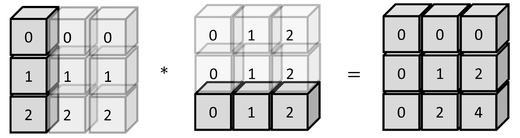

In [ ]:
z = np.arange(3)
print(np.outer(z, z))
print(z.reshape(3, 1) * z)       # the same, by broadcasting

**Order matters.** `X @ z` and `z @ X` are both valid for a `(3, 3)` matrix and a `(3,)` vector, but they are different: one combines rows, the other columns. Try both with `X = np.arange(9).reshape(3, 3)`.

**Memory.** `a.itemsize` gives the bytes per element and `a.nbytes` the total: an `int64` array of 4 values uses 32 bytes.

**More functions.** numpy has hundreds of mathematical functions: `np.sqrt`, `np.exp`, `np.round`, `np.cumsum`, `np.sort`, `np.unique`, `np.argsort`, and many more. Browse them in the [numpy mathematical functions reference](https://numpy.org/doc/stable/reference/routines.math.html).

In [ ]:
a = np.array([3, 1, 4, 1, 5, 9, 2, 6])
print(np.sort(a), np.unique(a), np.cumsum(a))
print(np.sqrt(a).round(2), a.itemsize, a.nbytes)

## Credits

Slicing-shapes figure: after Wes McKinney, *Python for Data Analysis* (O'Reilly). The house prices in Hour 3 and the measurements in the examples are made up for teaching.